> **Language & Quick Links**: [🇰🇷 Korean (`notebooks/ko/stage5_lineage_and_evaluation_ko.ipynb`)](../ko/stage5_lineage_and_evaluation_ko.ipynb) · **🇺🇸 English (Current Folder: `notebooks/en/`)** ｜ [Methodology Guide](../../methodology/en/05_stage5_lineage_and_eval_en.md) ｜ [Notebook Index (README)](../README.md) ｜ [Open Live Studio Tab](https://agentic-ontology-starter-lwrlf7yogq-du.a.run.app/?tab=stage5)
>
> **Lifecycle Navigation**: [0. End-to-End Overview](./stage0_overview_walkthrough_en.ipynb) → [Stage 1 · Prepare & Analyze](./stage1_asset_and_cq_en.ipynb) → [Stage 2 · Parse & Integrate](./stage2_wiki_and_semantic_graph_en.ipynb) → [Stage 3 · Build Property Graph](./stage3_property_graph_bigquery_spanner_en.ipynb) → [Stage 4 · Build Agent & Answer](./stage4_agent_and_mcp_execution_en.ipynb) → **[▶ Stage 5 · Verify & Evaluate](./stage5_lineage_and_evaluation_en.ipynb)**

---

# Stage 5. [Verify & Gate] End-to-End Data Lineage, Golden CQ Audit & 50-Trial Boundary Benchmark
## Step 5.1 Source File → Chunk → Rule → Contract → CQ Lineage · Step 5.2 5 Golden CQs & 10×5 Boundary Benchmark Release Gate

Stage 5 completes **Phase 8 (Verification & Release Gate)**. Using `mcp_stage5_lineage_and_eval` and `pipeline/validator.py`, we verify **(1) the End-to-End Data Lineage (`Source File → DocChunk → DomainRule → CustomerContract → Golden CQ`)**, **(2) deterministic SQL ground-truth auditing across all 5 Golden CQs**, **(3) 10 Boundary Cases × 5 repeated trials (50 live runs) for success, consistency, and intent stability**, and **(4) the Gate 1–5 Production Release Readiness Checklist**.

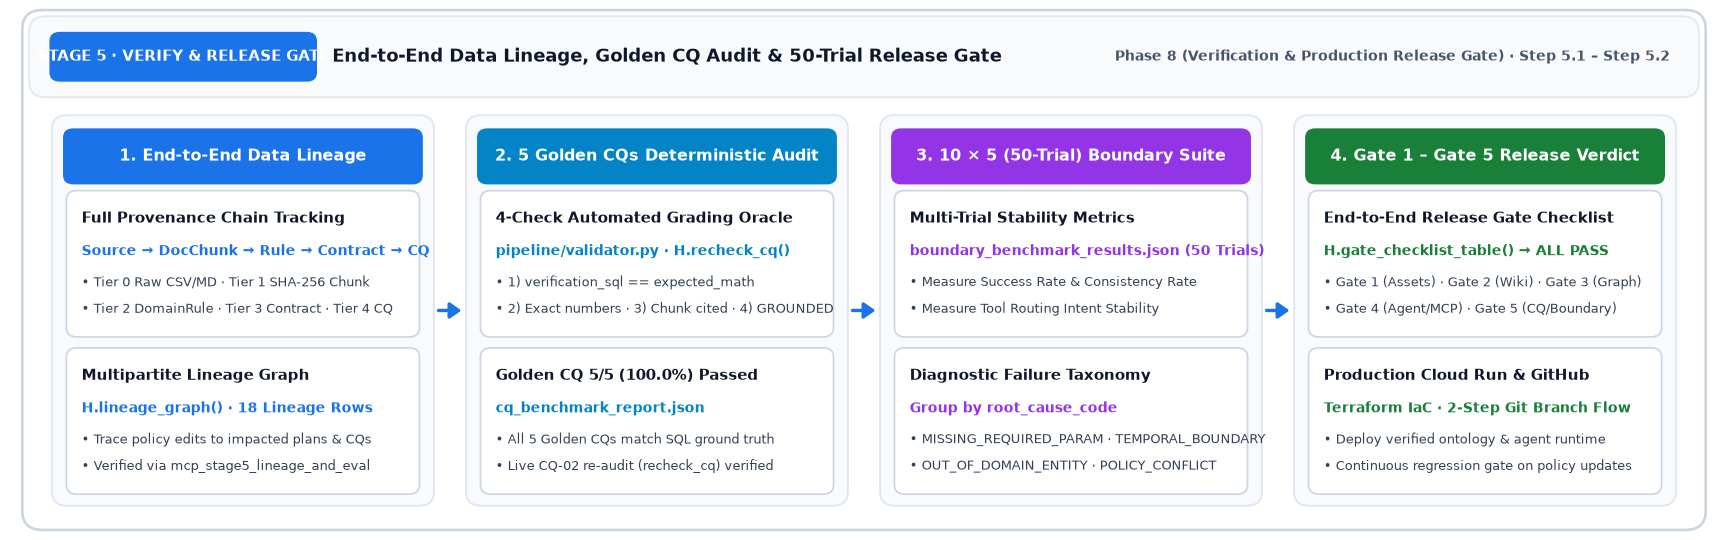


In [1]:
%load_ext bigframes
import sys
from pathlib import Path
for _p in (Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent):
    if (_p / "nb_helpers.py").exists() and str(_p) not in sys.path:
        sys.path.insert(0, str(_p))
import pandas as pd
import nb_helpers as H
from src.agent.mcp_server import DomainMcpServer
from src.agent.reasoning_engine import AiFdeAgentEngine
H.setup("en")
server = DomainMcpServer()
agent = AiFdeAgentEngine()


### 1. [Phase 8a: End-to-End Data Lineage Verification] `mcp_stage5_lineage_and_eval`, Lineage Join (`%%bqsql`) & Multipartite Lineage Graph


In [2]:
res_s5 = server.execute_tool("mcp_stage5_lineage_and_eval", {"steps": ["build_4tier_lineage", "run_golden_cq_suite", "diagnose_boundary_failures"]})
H.show_tool(res_s5)


**`mcp_stage5_lineage_and_eval`** · engine `bigquery` · status `SUCCESS` · steps `build_4tier_lineage, run_golden_cq_suite, diagnose_boundary_failures` · jobs 1 (490.1 ms)

12 lineage join rows (bigquery) · Latest validation report: {'evaluated_at': '2026-09-30T23:15:42+09:00', 'run_id': '20260930T231542-82b2d488', 'total_cqs': 5, 'passed': 5, 'accuracy_rate': 100.0, 'synthetic_basis': True, 'unconfirmed_cqs': 5, 'method': 'sql CQ: verification_sql(BigQuery) vs expected_math + live agent answer; citation CQ: agent answer must cite expected chunk and contain expected_facts (Vertex AI gemini-3.8-flash); every final answer is also scored by an LLM judge on a 100-point rubric (PASS verdict required) and checked for duplicates'}

- `job_LnO0X8kkJc7_y5XdyivfFZMHrZU9`

In [3]:
%%bqsql df_lineage
SELECT c.contract_id, c.customer_id, d.device_name, p.plan_name, s.policy_id,
       e.rule_id, e.source_chunk_id, ch.content_sha256 AS anchor, ch.source_file
FROM `seanjung-poc.starter_ontology_dw.tb_customer_contract` c
JOIN `seanjung-poc.starter_ontology_dw.tb_device_master` d ON d.device_id = c.device_id
JOIN `seanjung-poc.starter_ontology_dw.tb_plan_master` p ON p.plan_id = c.plan_id
LEFT JOIN `seanjung-poc.starter_ontology_dw.tb_subsidy_policy` s ON s.device_id = c.device_id AND s.plan_id = c.plan_id
LEFT JOIN `seanjung-poc.starter_ontology_dw.edge_rule_applies_to_plan` e ON e.plan_id = c.plan_id
LEFT JOIN `seanjung-poc.starter_ontology_dw.tb_doc_chunks` ch ON ch.chunk_id = e.source_chunk_id
ORDER BY c.contract_id, e.rule_id


,contract_id,customer_id,device_name,plan_name,policy_id,rule_id,source_chunk_id,anchor,source_file
0,CONTRACT_DEMO_101,CUST_DEMO_001,Galaxy S26 Ultra 256GB,5G Premier Essential,POL-2026-002,RULE_SIX_PLAN_180D,DOC_CHUNK_002,anchor_3003b683cea0,sample_policy_guide.md
1,CONTRACT_DEMO_101,CUST_DEMO_001,Galaxy S26 Ultra 256GB,5G Premier Essential,POL-2026-002,RULE_TCO_24M,DOC_CHUNK_005,anchor_4fbaf9c5cba8,sample_welfare_exemption_guide.md
2,CONTRACT_DEMO_102,CUST_DEMO_002,Galaxy S26 Ultra 256GB,5G Premier Super,POL-2026-001,RULE_SIX_PLAN_180D,DOC_CHUNK_002,anchor_3003b683cea0,sample_policy_guide.md
3,CONTRACT_DEMO_102,CUST_DEMO_002,Galaxy S26 Ultra 256GB,5G Premier Super,POL-2026-001,RULE_TCO_24M,DOC_CHUNK_005,anchor_4fbaf9c5cba8,sample_welfare_exemption_guide.md
4,CONTRACT_DEMO_103,CUST_DEMO_003,iPhone 16 Pro 256GB,5G Premier Essential,POL-2026-005,RULE_SIX_PLAN_180D,DOC_CHUNK_002,anchor_3003b683cea0,sample_policy_guide.md
5,CONTRACT_DEMO_103,CUST_DEMO_003,iPhone 16 Pro 256GB,5G Premier Essential,POL-2026-005,RULE_TCO_24M,DOC_CHUNK_005,anchor_4fbaf9c5cba8,sample_welfare_exemption_guide.md
6,CONTRACT_DEMO_104,CUST_DEMO_004,Galaxy S26 Ultra 512GB,5G Premier Essential,<NA>,RULE_SIX_PLAN_180D,DOC_CHUNK_002,anchor_3003b683cea0,sample_policy_guide.md
7,CONTRACT_DEMO_104,CUST_DEMO_004,Galaxy S26 Ultra 512GB,5G Premier Essential,<NA>,RULE_TCO_24M,DOC_CHUNK_005,anchor_4fbaf9c5cba8,sample_welfare_exemption_guide.md
8,CONTRACT_DEMO_105,CUST_DEMO_005,iPhone 16 Pro 512GB,5G Direct 61,<NA>,RULE_SIX_PLAN_180D,DOC_CHUNK_002,anchor_3003b683cea0,sample_policy_guide.md
9,CONTRACT_DEMO_105,CUST_DEMO_005,iPhone 16 Pro 512GB,5G Direct 61,<NA>,RULE_TCO_24M,DOC_CHUNK_005,anchor_4fbaf9c5cba8,sample_welfare_exemption_guide.md


,contract_id,customer_id,device_name,plan_name,policy_id,rule_id,source_chunk_id,anchor,source_file
0,CONTRACT_DEMO_101,CUST_DEMO_001,Galaxy S26 Ultra 256GB,5G Premier Essential,POL-2026-002,RULE_SIX_PLAN_180D,DOC_CHUNK_002,anchor_3003b683cea0,sample_policy_guide.md
1,CONTRACT_DEMO_101,CUST_DEMO_001,Galaxy S26 Ultra 256GB,5G Premier Essential,POL-2026-002,RULE_TCO_24M,DOC_CHUNK_005,anchor_4fbaf9c5cba8,sample_welfare_exemption_guide.md
2,CONTRACT_DEMO_102,CUST_DEMO_002,Galaxy S26 Ultra 256GB,5G Premier Super,POL-2026-001,RULE_SIX_PLAN_180D,DOC_CHUNK_002,anchor_3003b683cea0,sample_policy_guide.md
3,CONTRACT_DEMO_102,CUST_DEMO_002,Galaxy S26 Ultra 256GB,5G Premier Super,POL-2026-001,RULE_TCO_24M,DOC_CHUNK_005,anchor_4fbaf9c5cba8,sample_welfare_exemption_guide.md
4,CONTRACT_DEMO_103,CUST_DEMO_003,iPhone 16 Pro 256GB,5G Premier Essential,POL-2026-005,RULE_SIX_PLAN_180D,DOC_CHUNK_002,anchor_3003b683cea0,sample_policy_guide.md
5,CONTRACT_DEMO_103,CUST_DEMO_003,iPhone 16 Pro 256GB,5G Premier Essential,POL-2026-005,RULE_TCO_24M,DOC_CHUNK_005,anchor_4fbaf9c5cba8,sample_welfare_exemption_guide.md
6,CONTRACT_DEMO_104,CUST_DEMO_004,Galaxy S26 Ultra 512GB,5G Premier Essential,NaN,RULE_SIX_PLAN_180D,DOC_CHUNK_002,anchor_3003b683cea0,sample_policy_guide.md
7,CONTRACT_DEMO_104,CUST_DEMO_004,Galaxy S26 Ultra 512GB,5G Premier Essential,NaN,RULE_TCO_24M,DOC_CHUNK_005,anchor_4fbaf9c5cba8,sample_welfare_exemption_guide.md
8,CONTRACT_DEMO_105,CUST_DEMO_005,iPhone 16 Pro 512GB,5G Direct 61,NaN,RULE_SIX_PLAN_180D,DOC_CHUNK_002,anchor_3003b683cea0,sample_policy_guide.md
9,CONTRACT_DEMO_105,CUST_DEMO_005,iPhone 16 Pro 512GB,5G Direct 61,NaN,RULE_TCO_24M,DOC_CHUNK_005,anchor_4fbaf9c5cba8,sample_welfare_exemption_guide.md


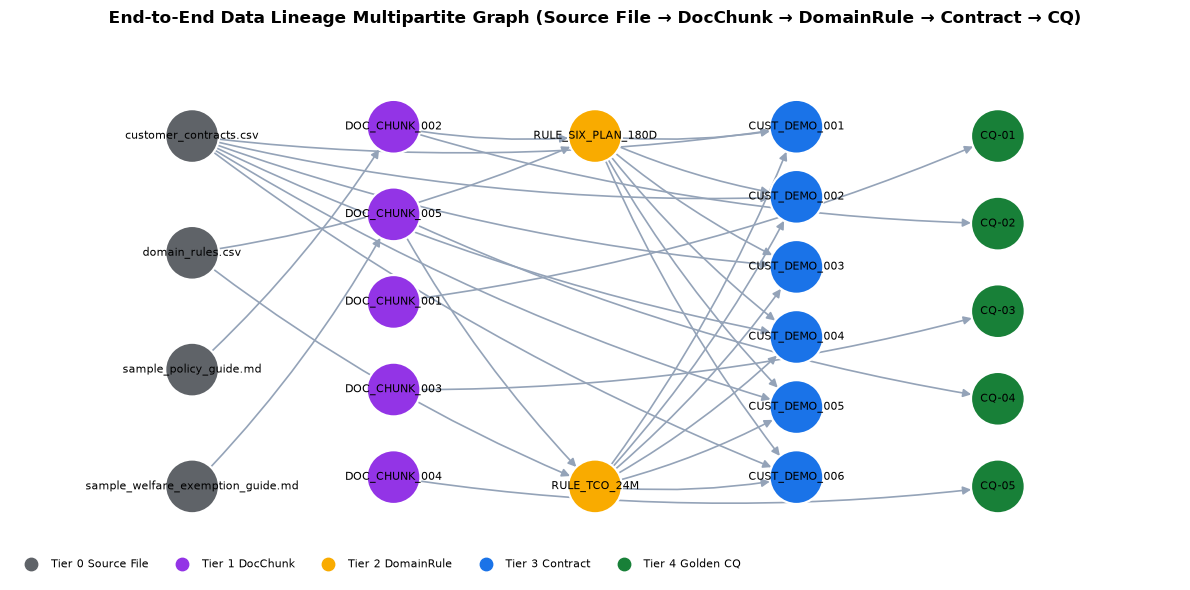

In [4]:
H.show(df_lineage)
cq_rep = H.read_json("data/output/cq_benchmark_report.json")
lnodes, ledges = H.lineage_graph(H.pdf(df_lineage).to_dict("records"), cq_rep["test_results"])
H.draw_graph(lnodes, ledges,
             "End-to-End Data Lineage Multipartite Graph (Source File → DocChunk → DomainRule → Contract → CQ)",
             layout="layers", figsize=(12, 6.0),
             legend={"Tier 0 Source File": "#5F6368", "Tier 1 DocChunk": "#9334E6", "Tier 2 DomainRule": "#F9AB00",
                     "Tier 3 Contract": "#1A73E8", "Tier 4 Golden CQ": "#188038"})


#### Studio lineage DAG (`config/lineage_spec.json`), measured
Same engine as the studio `Stage 5` lineage (`src/lineage/lineage_engine.py`). Volumes are BigQuery `__TABLES__` row counts, GCS object counts and node/edge table counts from `INFORMATION_SCHEMA.PROPERTY_GRAPHS`, queried now; a failed lookup stays `lookup failed`.

**Structure principle (method)**: one box per structured table and one box per edge-table kind. Unstructured documents flow RAW → parsed → re-extraction gate → latest → one box per ontology document; the Wiki Agent input is the ontology latest on GCS. The remote MCP server is not drawn as a box.

**Starter spec**: structured tables (`RAW_TB_*`) and edge tables (`TR_EDGE_*`) have one box each, and the graph layer has a separate node-label box per table (`SEM_NODE_*`). Unstructured documents flow from 2 guide boxes → chunker (`tb_doc_chunks`) → GCS `parsed/` and one wiki box (`gs://{bucket}/ontology/`). There is no re-extraction gate, no `latest` promotion, no per-document ontology box, no Wiki Agent box and no remote MCP server box.


In [5]:
from src.lineage.lineage_engine import LineageEngine
lg = LineageEngine(str(H.ROOT / "config" / "lineage_spec.json"), {
    "project_id": server.project_id, "fq": server.fq, "dataset_id": server.fq.split(".", 1)[1],
    "bucket": server.gcs_bucket, "model": agent.model_name,
    "spanner_instance": server.spanner_instance_id, "spanner_database": server.spanner_database_id}).build_graph()
H.md(f"**nodes `{lg['stats']['total_nodes']}` · edges `{lg['stats']['total_edges']}` · categories `{lg['stats']['total_categories']}` · "
     f"measured `{lg['metadata']['live_nodes']}/{lg['metadata']['bq_nodes']}` · errors `{lg['metadata']['bq_error'] or 0}`**")
H.show(pd.DataFrame([{"category": n["cat"], "node": n["id"], "volume": n["volume_en"], "measured": n["live"], "source": n["live_src"]}
                     for n in lg["nodes"] if n["live_src"]]))


**nodes `37` · edges `67` · categories `7` · measured `21/21` · errors `0`**

,category,node,volume,measured,source
0,RAW_DATASETS,RAW_TB_DEVICE,4 rows,True,BigQuery __TABLES__ (job_Olb4pg8yoM2XDQvjq_3kKHh8xZsE)
1,RAW_DATASETS,RAW_TB_PLAN,6 rows,True,BigQuery __TABLES__ (job_Olb4pg8yoM2XDQvjq_3kKHh8xZsE)
2,RAW_DATASETS,RAW_TB_SUBSIDY,5 rows,True,BigQuery __TABLES__ (job_Olb4pg8yoM2XDQvjq_3kKHh8xZsE)
3,RAW_DATASETS,RAW_TB_CONTRACT,6 rows,True,BigQuery __TABLES__ (job_Olb4pg8yoM2XDQvjq_3kKHh8xZsE)
4,RAW_DATASETS,RAW_TB_RULES,4 rows,True,BigQuery __TABLES__ (job_Olb4pg8yoM2XDQvjq_3kKHh8xZsE)
5,RAW_DATASETS,RAW_GCS,2 objects,True,GCS JSON API objects.list
6,DATA_TRANSFORMATION,TR_CHUNKER,5 rows,True,BigQuery __TABLES__ (job_Olb4pg8yoM2XDQvjq_3kKHh8xZsE)
7,DATA_TRANSFORMATION,TR_GCS_PARSED,1 objects,True,GCS JSON API objects.list
8,DATA_TRANSFORMATION,TR_EDGE_CONTRACT_DEVICE,6 rows,True,BigQuery __TABLES__ (job_Olb4pg8yoM2XDQvjq_3kKHh8xZsE)
9,DATA_TRANSFORMATION,TR_EDGE_CONTRACT_PLAN,6 rows,True,BigQuery __TABLES__ (job_Olb4pg8yoM2XDQvjq_3kKHh8xZsE)


### 2. [Phase 8b: 5 Golden CQs Deterministic Audit (`pipeline/validator.py`)] Benchmark Report & Live Agent Re-Verification (`recheck_cq`)


#### Evaluation order: A overall results → B per-CQ verification → C rubric criteria
A is the pass count, rubric average, number of CQs with deductions and per-axis averages. B is, per CQ, the expected value and verification SQL result, score, verdict and deduction count, and evidence (cited chunk, verification job ID, agent BigQuery job count, judge summary). C is the rubric axis definitions. All values are read from `data/output/cq_benchmark_report.json`. The starter report stores rubric descriptions in English only (no `name_ko`, `desc_ko`, `judge_instructions_ko` fields). The answer text is stored in Korean, so the Korean notebook adds an answer excerpt per CQ and this English notebook shows the judge summary only. Finally, `CQ-02` is re-run now to check the grading conditions.


#### A. Overall results

**Golden CQ Benchmark `STARTER_GOLDEN_CQ_LIVE`** · Evaluated `2026-09-30T23:15:42+09:00` · Model `gemini-3.8-flash` · Passed **`5/5 (100.0%)`** · Rubric avg `100.0` · CQs with deductions `0` · LLM tokens `32,655`

,relevance,accuracy,completeness,grounding,actionability
0,20.0,30.0,20.0,15.0,15.0


#### B. Per-CQ verification (score and evidence)

,cq_id,status,expected_math,verification_sql_result,verification_job_id,score,verdict,deductions,grounded_chunk,agent_bq_jobs,llm_tokens,elapsed_s,judge_summary
0,CQ-01,PASSED,{'factory_price': 1698400},{'factory_price': 1698400},job_DHYvRBqk0k0Pa2P_3k50cG0iq9Jc,100,PASS,0,DOC_CHUNK_001,3,7398,12.54,"The answer provides the exact official factory price of 1,698,400 KRW right upfront, f..."
1,CQ-02,PASSED,"{'subsidy': 517500, 'net_price': 1180900}","{'subsidy': 517500, 'net_price': 1180900}",job_1tfMk3GO_-XIsot93UdNKA34uyqH,100,PASS,0,DOC_CHUNK_002,3,4644,12.39,The response provides the exact total subsidy and net device purchase price with perfe...
2,CQ-03,PASSED,{'penalty': 100000},{'penalty': 100000},job_JyTBL0S23XP3yMEtkqSYhUOjzWys,100,PASS,0,DOC_CHUNK_003,5,6839,16.87,"The response provides an accurate, perfectly grounded, and comprehensive calculation o..."
3,CQ-04,PASSED,"{'public_subsidy_total': 517500, 'selective_discount_total': 510000, 'tco_savings': 7500}","{'public_subsidy_total': 517500, 'selective_discount_total': 510000, 'tco_savings': 7500}",job_jjBBgf1uM-d0l2TrDoU55AzmpPpU,100,PASS,0,DOC_CHUNK_005,5,6919,17.75,"The answer provides a clear, accurate, and perfectly grounded comparison identifying p..."
4,CQ-05,PASSED,"{'penalty': 0, 'exemption_rule': 'RULE_WELFARE_EXEMPT'}","{'penalty': 0, 'exemption_rule': 'RULE_WELFARE_EXEMPT'}",job_tmZ4DJRVEzFJLi4uE7i1VZZLBjYq,100,PASS,0,DOC_CHUNK_004,5,6855,19.09,The answer accurately concludes that the penalty is 0 KRW due to senior welfare exempt...


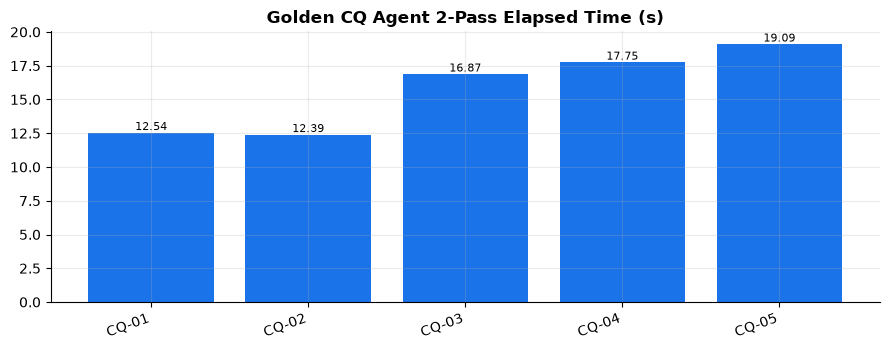

#### C. Rubric criteria

,key,max,desc
0,relevance,20,Answers the question actually asked (not a neighbouring topic); conclusion comes first.
1,accuracy,30,"Facts, formulas, conditions and numbers match the expected answer and the evidence."
2,completeness,20,Covers every sub-question and required condition.
3,grounding,15,Every number and rule is backed by the retrieved evidence; nothing invented.
4,actionability,15,"Clear, non-hedged conclusion plus useful related information (exceptions, caveats)."


#### Live Re-Audit: CQ-02
**Q.** When activating a Galaxy S26 Ultra 256GB on the 5G Premier Essential (85,000 KRW) plan, what are the total subsidy and net purchase price?

- **Step 1 (Decomposition & Slot Extraction)**: sub-goals - · params `{"device_name": "Galaxy S26 Ultra 256GB", "plan_name": "5G Premier Essential", "monthly_fee_krw": 85000, "device_mention": "Galaxy S26 Ultra 256GB", "plan_mention": "5G Premier Essential"}`
- **Step 2 (Deterministic MCP Tool Dispatch)**:

| # | MCP Tool | Status | Rows/Paths | BigQuery ms | BigQuery Job ID |
|---:|:---|:---|---:|---:|:---|
| 1 | `mcp_lookup_customer_profile` | `SUCCESS` | 1 | 502 | `job_bWPoXlz-ddRn2wNB5stC2SPPSXYa` |
| 2 | `mcp_query_graph_and_wiki` | `SUCCESS` | 2 | 571 | `job_xGNGJ7UzHv7Vxp6Dpoj_cEvdvPTd` |

- **`mcp_query_graph_and_wiki` Executed GQL & Bound Variables** (`params={"device_name": "Galaxy S26 Ultra 256GB", "plan_name": "5G Premier Essential", "monthly_fee_krw": 85000, "device_mention": "Galaxy S26 Ultra 256GB", "plan_mention": "5G Premier Essential"}`):
```sql
SELECT g.*, ch.section_title, ch.content_sha256 AS anchor, ch.content AS chunk_text
FROM GRAPH_TABLE(`seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
  MATCH (d:DeviceNode)-[hs:HAS_SUBSIDY_POLICY]->(p:PlanNode)<-[ap:APPLIES_TO_PLAN]-(r:DomainRuleNode)
  COLUMNS (hs.policy_id AS policy_id, hs.total_subsidy_krw AS total_subsidy_krw, d.device_name AS device_name, d.factory_price_krw AS factory_price_krw,
           p.plan_name AS plan_name, p.monthly_fee_krw AS monthly_fee_krw,
           r.rule_id AS rule_id, r.rule_name AS rule_name,
           ap.relation_label_ko AS relation_label_ko, ap.source_chunk_id AS source_chunk_id)) g
LEFT JOIN `seanjung-poc.starter_ontology_dw.tb_doc_chunks` ch ON ch.chunk_id = g.source_chunk_id
WHERE g.device_name = 'Galaxy S26 Ultra 256GB' AND g.plan_name = '5G Premier Essential' AND g.monthly_fee_krw = 85000
ORDER BY g.device_name, g.monthly_fee_krw DESC, g.rule_id
```

- **Step 3 (Grounding & Guardrail Verdict)**: `answer_status=GROUNDED` · anchors `[]` · Gemini `gemini-3.8-flash` (2 calls, 4,666 tokens, LLM 51,299 ms / total 52.85 s)

- **Step 4 (Synthesized Grounded Answer)**:

> ### Conclusion
> When activating the **Galaxy S26 Ultra 256GB** on the **5G Premier Essential** (85,000 KRW/month) plan, the **total subsidy** is **517,500 KRW** and the resulting **net purchase price** (net installment principal) is **1,180,900 KRW**.
>
> ---
>
> ### Grounded Data (BigQuery)
> * **Device Name**: Galaxy S26 Ultra 256GB (`DEV-S26U-256`, 256GB)
> * **Plan Name**: 5G Premier Essential (`PLAN-5G-85`, 85,000 KRW/month)
> * **Policy ID**: `POL-2026-002`
> * **Factory Price**: 1,698,400 KRW
> * **Base Subsidy**: 450,000 KRW
> * **Additional Subsidy Cap**: 67,500 KRW
> * **Total Subsidy**: 517,500 KRW (Formula: `Base Subsidy (450,000 KRW) + Additional Subsidy Cap (67,500 KRW)`)
> * **Net Purchase Price (Installment Principal)**: 1,180,900 KRW (Formula: `Factory Price (1,698,400 KRW) - Total Subsidy (517,500 KRW)`)
>
> ---
>
> ### Applied Rules & Source Chunks
> * **`RULE_SUBSIDY_CAP`**
>   * **Chunk ID**: `DOC_CHUNK_001`
> * **`RULE_SIX_PLAN_180D`** (180-Day Baseline (45,000 KRW) Mandatory Retention & Prorated Penalty Rule)
>   * **Chunk ID**: `DOC_CHUNK_002`
>   * **Anchor**: `anchor_3003b683cea0`
> * **`RULE_TCO_24M`** (24-Month Public Subsidy vs. 25% Selective Contract TCO Comparison Rule)
>   * **Chunk ID**: `DOC_CHUNK_005`
>   * **Anchor**: `anchor_4fbaf9c5cba8`
>
> ---
>
> ### Related Information
> 1. **Mandatory Retention Period**: Subscribers receiving public device subsidies must maintain their initial subscription tier at or above the designated baseline plan threshold (e.g., 5G 45,000 KRW/month) for a mandatory duration of **180 days** from activation.
> 2. **Clawback Penalty**: If the subscription tier is downgraded below the baseline threshold within 180 days, a prorated subsidy difference clawback penalty is levied based on elapsed days.
> 3. **Alternative 25% Selective Discount Comparison**: Under `RULE_TCO_24M`, customers may evaluate a 25% selective discount path against the public subsidy path over 24 months to identify the optimal Total Cost of Ownership (TCO).
>
> ---
>
> ### Execution Telemetry
> * **BigQuery Job IDs**:
>   * `job_bWPoXlz-ddRn2wNB5stC2SPPSXYa` (Profile and subsidy lookup)
>   * `job_xGNGJ7UzHv7Vxp6Dpoj_cEvdvPTd` (Property graph and documentation chunk traversal)

,check,passed,detail
0,verification_sql == expected_math,True,"{'subsidy': 517500, 'net_price': 1180900} (job job_T2qG0LHQ766fdpJ8rsfYIm1KM4n_)"
1,"answer contains subsidy = 517,500",True,
2,"answer contains net_price = 1,180,900",True,
3,answer cites DOC_CHUNK_002,True,
4,answer_status == GROUNDED,True,GROUNDED


In [6]:
df_cq = pd.DataFrame(cq_rep["test_results"])
H.md("#### A. Overall results")
H.md(f"**Golden CQ Benchmark `{cq_rep['benchmark_id']}`** · Evaluated `{cq_rep['evaluated_at']}` · Model `{cq_rep['model']}` · Passed **`{cq_rep['passed']}/{cq_rep['total_cqs']} ({cq_rep['accuracy_rate']}%)`** · "
     f"Rubric avg `{cq_rep['rubric_avg_total']}` · CQs with deductions `{sum(1 for r in cq_rep['test_results'] if r['rubric']['deductions'])}` · LLM tokens `{cq_rep['llm_tokens_total']:,}`")
H.show(pd.DataFrame([cq_rep["rubric_axis_avg"]]))

H.md("#### B. Per-CQ verification (score and evidence)")
df_cq["score"] = df_cq["rubric"].map(lambda r: r["scores"]["total"])
df_cq["verdict"] = df_cq["rubric"].map(lambda r: r["verdict"])
df_cq["deductions"] = df_cq["rubric"].map(lambda r: len(r["deductions"]))
df_cq["judge_summary"] = df_cq["rubric"].map(lambda r: r["summary"])
df_cq["agent_bq_jobs"] = df_cq["agent_bq_job_ids"].map(len)
H.show(df_cq, ["cq_id", "status", "expected_math", "verification_sql_result", "verification_job_id", "score", "verdict", "deductions",
               "grounded_chunk", "agent_bq_jobs", "llm_tokens", "elapsed_s", "judge_summary"])
H.bar(df_cq, "cq_id", "elapsed_s", "Golden CQ Agent 2-Pass Elapsed Time (s)", fmt="{:.2f}")

H.md("#### C. Rubric criteria")
H.show(pd.DataFrame(cq_rep["rubric"]))

cqs = H.read_json("data/input/04_cq/golden_competency_questions.json")
res_cq2, df_chk = H.recheck_cq(cqs[1], agent)
H.show_agent(res_cq2, title="Live Re-Audit: CQ-02")
H.show(df_chk)


### 3. [Phase 8c: 10 Boundary Cases × 5 Trials (50 Runs) Stability Evaluation & Gate 1–5 Release Verdict]


**Boundary Benchmark `STARTER_BOUNDARY_LIVE`** · Trials=`50` · avg_success_rate=`96.0%` · avg_consistency_rate=`92.0%` · avg_intent_stability=`78.0%`

,case_id,root_cause_code,missing_context,trials,passed_trials,success_rate,consistency_rate,intent_stability
0,BQ-01,NO_SLOT_FILLING,"Missing customer ID, current plan, and target downgrade plan",5,5,100.0,100.0,80.0
1,BQ-02,MISSING_EXCEPTION_EDGE,Missing Senior Welfare exemption registration status (customer ID),5,4,80.0,80.0,80.0
2,BQ-03,NO_SLOT_FILLING,Unspecified storage capacity (256GB/512GB) and subscription plan,5,5,100.0,100.0,80.0
3,BQ-04,MISSING_ENTITY,Military enlistment suspension rule reference,5,5,100.0,100.0,80.0
4,BQ-05,NO_ALIAS_DICT,Device alias ('latest iPhone Pro') and unspecified tariff plan,5,5,100.0,60.0,60.0
5,BQ-06,NO_SLOT_FILLING,Post-180-day full exemption boundary condition,5,5,100.0,100.0,60.0
6,BQ-07,MISSING_ENTITY,Node table duplicate-key metadata inspection,5,5,100.0,100.0,100.0
7,BQ-08,MISSING_EXCEPTION_EDGE,"Downgrade between plans above the 45,000 KRW baseline threshold",5,5,100.0,100.0,80.0
8,BQ-09,MISSING_ENTITY,Corporate_B2B segment policy mapping,5,5,100.0,100.0,100.0
9,BQ-10,NO_ALIAS_DICT,BigQuery Property Graph vs. Cloud Spanner Graph ISO GQL compatibility,5,4,80.0,80.0,60.0


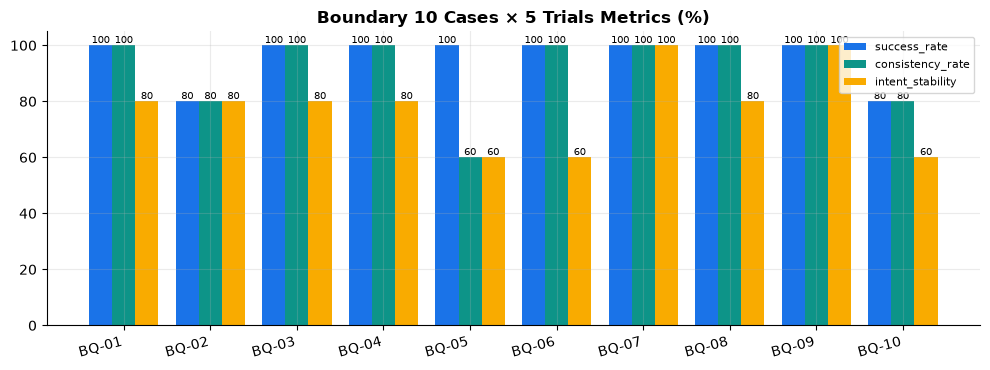

,root_cause_code,cases,avg_success,avg_consistency,avg_intent_stability
0,MISSING_ENTITY,3,100.0,100.0,93.333333
1,MISSING_EXCEPTION_EDGE,2,90.0,90.0,80.000000
2,NO_ALIAS_DICT,2,90.0,70.0,60.000000
3,NO_SLOT_FILLING,3,100.0,100.0,73.333333


#### Gate 1 – Gate 5 Production Release Readiness Verdict

,gate,criterion,measured_value,verdict
0,Gate 1 (Stage 1: Prepare & Analyze),"10 BQ tables loaded, 0 PII violations, 5 CQ SQL matches","tables=10/10, CQs=5",PASS
1,Gate 2 (Stage 2: Parse & Integrate),5 SHA-256 chunks anchored & 3-Layer Wiki synced to GCS,"chunks=5, status=LIVE_GCP_SYNCED",PASS
2,Gate 3 (Stage 3: Build Property Graph),STARTER_ONTOLOGY_GRAPH DDL SUCCESS & 0 duplicate node keys,"ddl=SUCCESS, dup_keys=0",PASS
3,Gate 4 (Stage 4: Agent & MCP Runtime),8 MCP tools active & guardrail statuses verified,"8 MCP tools (5 Stage + 3 Runtime), 2-Pass Gemini Engine",PASS
4,Gate 5 (Stage 5: Lineage & Release Gate),Golden CQ 5/5 (100%) & Boundary 10x5 (50 trials) benchmark passed,"CQ=5/5 (100.0%), Boundary=96.0% (50 trials)",PASS


In [7]:
b_rep = H.read_json("data/output/boundary_benchmark_results.json")
df_bc = pd.DataFrame(b_rep["cases"])
H.md(f"**Boundary Benchmark `{b_rep['benchmark_id']}`** · Trials=`{b_rep['total_trials']}` · "
     f"avg_success_rate=`{b_rep['avg_success_rate']}%` · avg_consistency_rate=`{b_rep['avg_consistency_rate']}%` · "
     f"avg_intent_stability=`{b_rep['avg_intent_stability']}%`")
H.show(df_bc, ["case_id", "root_cause_code", "missing_context", "trials", "passed_trials", "success_rate", "consistency_rate", "intent_stability"])
H.grouped_bar(df_bc, "case_id", ["success_rate", "consistency_rate", "intent_stability"],
              "Boundary 10 Cases × 5 Trials Metrics (%)")
df_tax = df_bc.groupby("root_cause_code", as_index=False).agg(
    cases=("case_id", "count"), avg_success=("success_rate", "mean"),
    avg_consistency=("consistency_rate", "mean"), avg_intent_stability=("intent_stability", "mean"))
H.show(df_tax)
H.md("#### Gate 1 – Gate 5 Production Release Readiness Verdict")
H.show(H.gate_checklist_table())


### Q&A
- **Q.** How does `pipeline/validator.py` grade agent accuracy and verify zero hallucination?
  - **A.** For every Golden CQ it checks (1) independent BigQuery `verification_sql` matches `expected_math`, (2) the answer contains the expected values (`_has` regex), (3) the required `DOC_CHUNK` is cited, (4) `answer_status == GROUNDED`, and (5) scores the final answer with an LLM rubric (`_judge`); answers that are near-duplicates across CQs (3-gram overlap) fail.

### Data Analysis Key Findings
- The end-to-end lineage join (`df_lineage`, 18 rows) traces every Golden CQ answer back through customer contracts, codified domain rules, and SHA-256 `DOC_CHUNK` anchors to the raw CSV and Markdown source files.
- Golden CQ report (2026-09-30): 5/5 passed (`100.0%`), rubric average `100.0`. See the table above for the live `CQ-02` re-check. Starter CQs ask for single values, so full scores are easy to reach.
- Boundary report (2026-09-27, 50 trials): average success `96.0%`, consistency `92.0%`, intent stability `78.0%`. The Gate 1–5 verdict follows the table above.

### Insights or Next Steps
- You have completed the full 5-Stage Agentic Ontology walkthrough! Use the navigation links below to revisit `0. Overview Home` or any Stage notebook (KO/EN), or replace `data/input/` with your own domain tables and policy guides.

---
> **Next Navigation**: [⬅️ Stage 4 · Build Agent & Answer](./stage4_agent_and_mcp_execution_en.ipynb) ｜ [🏠 0. Overview Home](./stage0_overview_walkthrough_en.ipynb) ｜ [🌐 Korean Version](../ko/stage5_lineage_and_evaluation_ko.ipynb) ｜ [📖 Methodology Doc](../../methodology/en/05_stage5_lineage_and_eval_en.md)
